In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("GPU NOT detected")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB


In [ ]:
!pip install -q opencv-python pillow matplotlib numpy pandas

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Libraries loaded successfully!")

OpenCV: 4.14.0
NumPy: 2.1.3
Libraries loaded successfully!


In [ ]:
!git clone https://github.com/facebookresearch/sam2.git

fatal: destination path 'sam2' already exists and is not an empty directory.


In [ ]:
%cd /content/sam2
!pip install -e .

/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
  Created wheel for SAM-2: filename=sam_2-1.0-0.editable-cp313-cp313-linux_x86_64.whl size=13851 sha256=d87c5e71393e0396060c0e7ea9f6a2648be6d95e500ffd020b32f58a0d245d67
  Stored in directory: /tmp/pip-ephem-wheel-cache-xlmo7jt2/wheels/64/e2/28/d1780fb444d6d91bdaddca8d1cc2203826a9783d0f6c5c6e84
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.3-py3-none-any.whl size=144590 sha256=56b562fd

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

import sam2

print("SAM 2 imported successfully!")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
SAM 2 imported successfully!


In [ ]:
!pip install -q huggingface_hub

In [ ]:
from huggingface_hub import hf_hub_download

print("Hugging Face Hub ready!")

Hugging Face Hub ready!


In [ ]:
import torch
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 loaded successfully!")

Loading SAM 2.1 Small...


sam2.1_hiera_small.pt: reconstructing file:   0%|          |  0.00B /  184MB            

sam2.1_hiera_small.pt: downloading bytes:           |  0.00B            

SAM 2.1 loaded successfully!


In [ ]:
import os
import sys

# Move into the SAM 2 repository directory
os.chdir("/content/sam2")

# Make the repository directory the first import location
if "/content" in sys.path:
    sys.path.remove("/content")
if "/content/sam2" not in sys.path:
    sys.path.insert(0, "/content/sam2")

print("Current directory:", os.getcwd())

Current directory: /content/sam2


In [ ]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 Small loaded successfully!")

Loading SAM 2.1 Small...
SAM 2.1 Small loaded successfully!


In [ ]:
import os
import sys

# Stay outside the cloned SAM 2 repository
os.chdir("/tmp")

# Remove paths that can shadow the installed SAM 2 package
sys.path = [
    p for p in sys.path
    if p not in ("", "/content", "/content/sam2")
]

print("Current directory:", os.getcwd())
print("SAM2 repo path removed from sys.path")

Current directory: /tmp
SAM2 repo path removed from sys.path


In [ ]:
import sam2

print("SAM2 package:", sam2.__file__)

from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM 2 imported successfully!")

SAM2 package: /content/sam2/sam2/__init__.py
SAM 2 imported successfully!


In [ ]:
print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 Small loaded successfully!")

Loading SAM 2.1 Small...
SAM 2.1 Small loaded successfully!


In [ ]:
import urllib.request

image_url = "https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/truck.jpg"
image_path = "/content/truck.jpg"

urllib.request.urlretrieve(image_url, image_path)

print("Test image downloaded successfully!")
print("Path:", image_path)

Test image downloaded successfully!
Path: /content/truck.jpg


Image size: (1800, 1200)


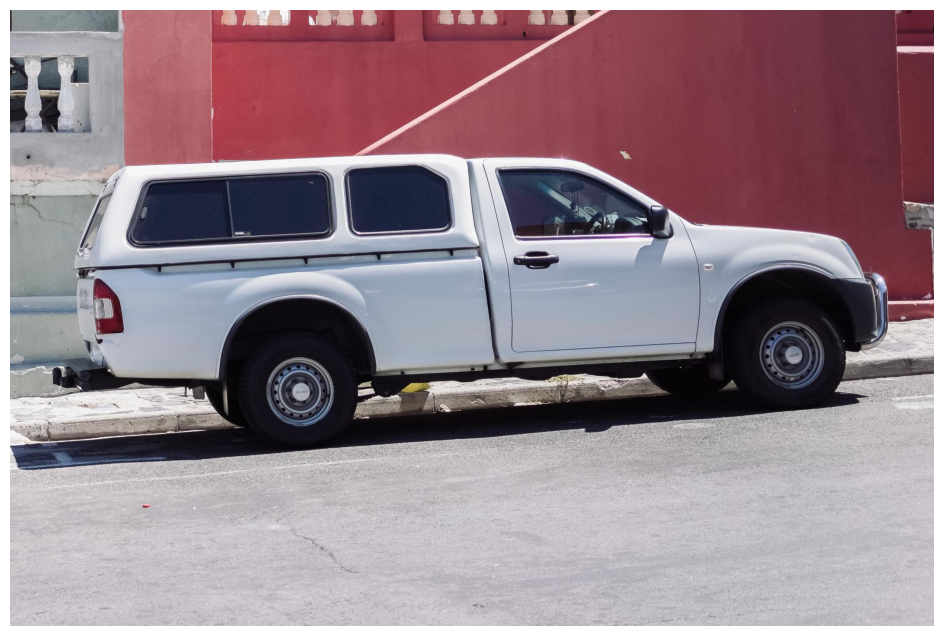

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
import numpy as np

image_np = np.array(image)

print("Width:", image_np.shape[1])
print("Height:", image_np.shape[0])

Width: 1800
Height: 1200


In [ ]:
import numpy as np

point_coords = np.array([[900, 650]])
point_labels = np.array([1])

print("Selected point:", point_coords[0])

Selected point: [900 650]


In [ ]:
predictor.set_image(image_np)

masks, scores, logits = predictor.predict(
    point_coords=point_coords,
    point_labels=point_labels,
    multimask_output=True
)

best_index = np.argmax(scores)

best_mask = masks[best_index]
best_score = scores[best_index]

print("Number of masks:", len(masks))
print("Best mask score:", best_score)
print("Mask shape:", best_mask.shape)

Number of masks: 3
Best mask score: 0.90025955
Mask shape: (1200, 1800)


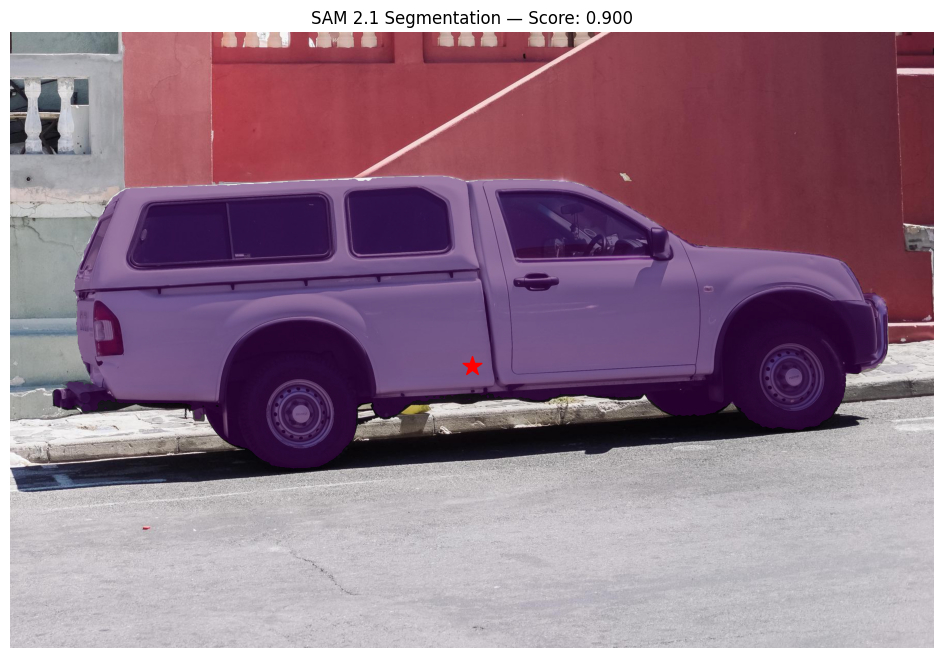

In [ ]:
# Convert SAM 2 output to a Boolean mask
mask = best_mask.astype(bool)

plt.figure(figsize=(12, 8))

# Original image
plt.imshow(image_np)

# Segmentation mask
plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.5
)

# Prompt point
plt.scatter(
    point_coords[:, 0],
    point_coords[:, 1],
    color="red",
    marker="*",
    s=200
)

plt.axis("off")
plt.title(f"SAM 2.1 Segmentation — Score: {best_score:.3f}")
plt.show()

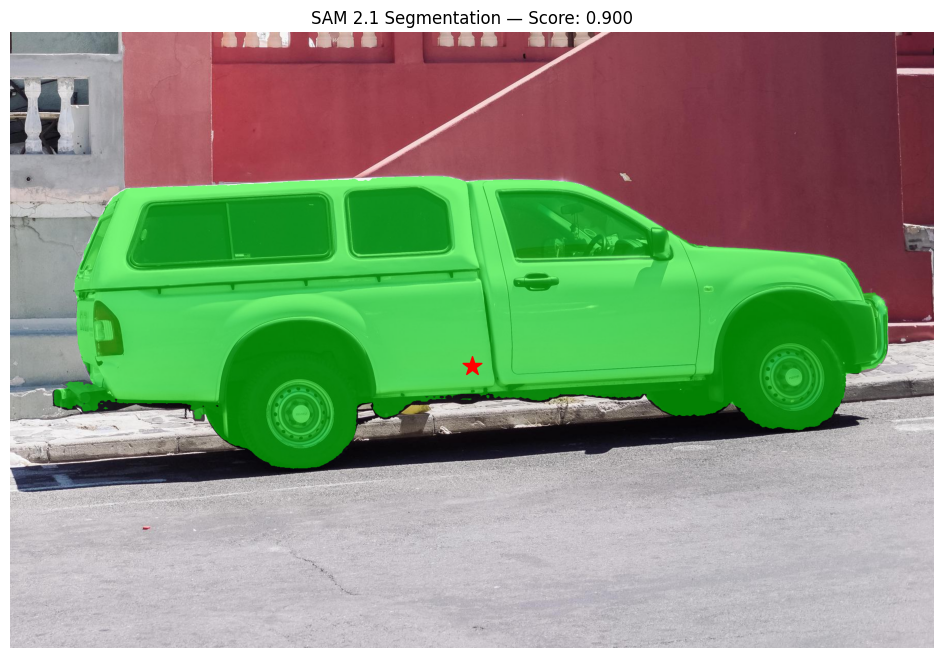

In [ ]:
mask = best_mask.astype(bool)

overlay = image_np.copy()

# Make the selected region brighter
overlay[mask] = (
    0.5 * overlay[mask] +
    0.5 * np.array([0, 255, 0])
).astype(np.uint8)

plt.figure(figsize=(12, 8))
plt.imshow(overlay)

plt.scatter(
    point_coords[:, 0],
    point_coords[:, 1],
    color="red",
    marker="*",
    s=200
)

plt.axis("off")
plt.title(f"SAM 2.1 Segmentation — Score: {best_score:.3f}")
plt.show()

In [ ]:
%cd /content

!git clone https://github.com/IDEA-Research/GroundingDINO.git

/content
Cloning into 'GroundingDINO'...
remote: Enumerating objects: 463, done.
remote: Counting objects: 100% (200/200), done.
remote: Compressing objects: 100% (68/68), done.
remote: Total 463 (delta 154), reused 132 (delta 132), pack-reused 263 (from 1)
Receiving objects: 100% (463/463), 12.87 MiB | 32.07 MiB/s, done.
Resolving deltas: 100% (243/243), done.


In [ ]:
%cd /content/GroundingDINO
!pip install -q -e .

/content/GroundingDINO
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build editable did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build editable ... error
ERROR: Failed to build 'file:///content/GroundingDINO' when getting requirements to build editable


In [ ]:
!pip install -q -U transformers

In [ ]:
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

device = "cuda" if torch.cuda.is_available() else "cpu"

model_id = "IDEA-Research/grounding-dino-tiny"

print("Loading Grounding DINO...")
print("Device:", device)

processor = AutoProcessor.from_pretrained(model_id)

grounding_model = AutoModelForZeroShotObjectDetection.from_pretrained(
    model_id
).to(device)

print("Grounding DINO loaded successfully!")

Loading Grounding DINO...
Device: cuda


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

Grounding DINO loaded successfully!


In [ ]:
text_labels = [["truck"]]

inputs = processor(
    images=image,
    text=text_labels,
    return_tensors="pt"
).to(device)

with torch.no_grad():
    outputs = grounding_model(**inputs)

results = processor.post_process_grounded_object_detection(
    outputs,
    inputs.input_ids,
    threshold=0.3,
    text_threshold=0.25,
    target_sizes=[image.size[::-1]]
)

result = results[0]

print("Detected objects:", len(result["boxes"]))

for box, score, label in zip(
    result["boxes"],
    result["scores"],
    result["text_labels"]
):
    print(
        "Object:",
        label,
        "| Confidence:",
        round(score.item(), 3),
        "| Box:",
        [round(x, 1) for x in box.tolist()]
    )

Detected objects: 1
Object: truck | Confidence: 0.687 | Box: [93.1, 277.5, 1713.6, 852.0]


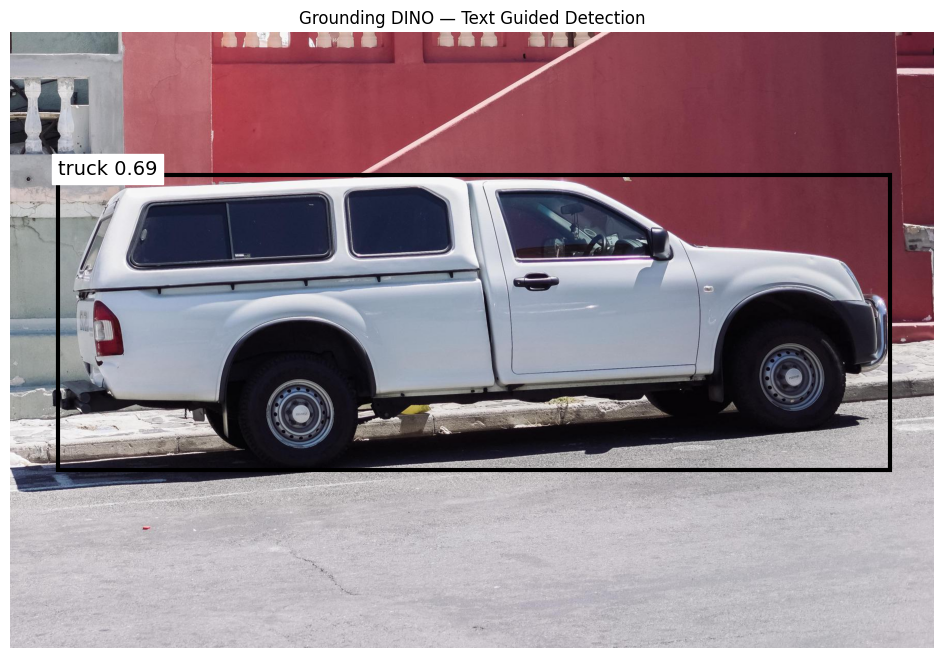

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.figure(figsize=(12, 8))
plt.imshow(image)

ax = plt.gca()

for box, score, label in zip(
    result["boxes"],
    result["scores"],
    result["text_labels"]
):
    x1, y1, x2, y2 = box.cpu().numpy()

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=3
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{label} {score:.2f}",
        fontsize=14,
        backgroundcolor="white"
    )

plt.axis("off")
plt.title("Grounding DINO — Text Guided Detection")
plt.show()

In [ ]:
# Take the highest-confidence detected box
best_detection = result["scores"].argmax()

box = result["boxes"][best_detection].cpu().numpy()

print("Selected bounding box:")
print(box)

Selected bounding box:
[  93.11991  277.49338 1713.6129   852.0269 ]


In [ ]:
# Prepare image for SAM 2
predictor.set_image(image_np)

# Convert box to the format SAM 2 expects
box = box.astype(np.float32)

masks, scores, logits = predictor.predict(
    box=box,
    multimask_output=True
)

best_mask_index = np.argmax(scores)

best_mask = masks[best_mask_index].astype(bool)
best_mask_score = scores[best_mask_index]

print("SAM 2 mask score:", best_mask_score)
print("Mask size:", best_mask.shape)

SAM 2 mask score: 0.9868081
Mask size: (1200, 1800)


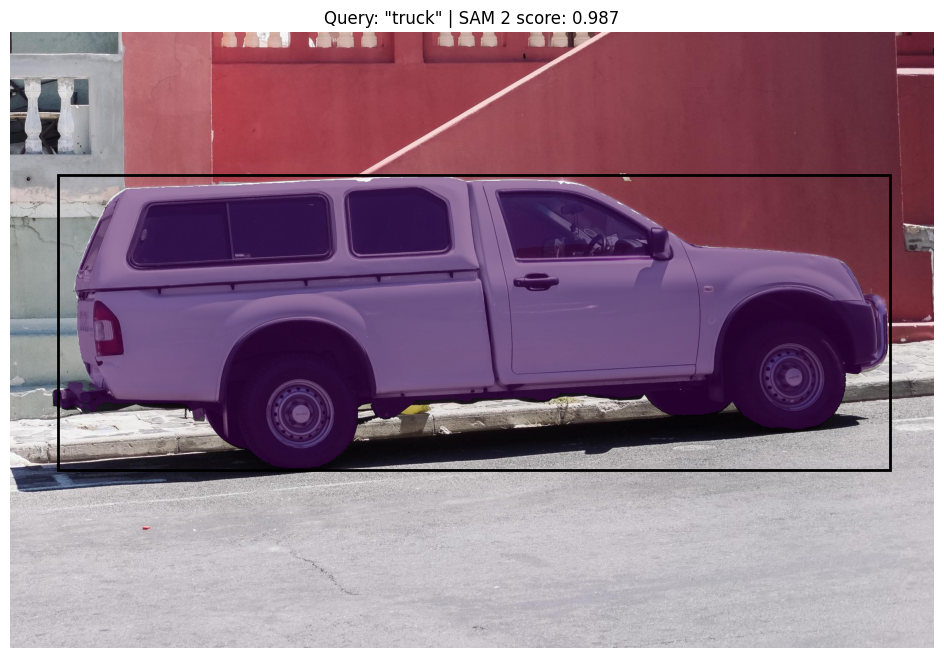

In [ ]:
plt.figure(figsize=(12, 8))

plt.imshow(image_np)

plt.imshow(
    np.ma.masked_where(~best_mask, best_mask),
    alpha=0.5
)

x1, y1, x2, y2 = box

rect = Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    fill=False,
    linewidth=2
)

plt.gca().add_patch(rect)

plt.axis("off")

plt.title(
    f'Query: "truck" | '
    f'SAM 2 score: {best_mask_score:.3f}'
)

plt.show()

In [ ]:
import urllib.request
import os

video_url = "https://github.com/facebookresearch/sam2/raw/main/demo/data/gallery/01_dog.mp4"
video_path = "/content/test_video.mp4"

urllib.request.urlretrieve(video_url, video_path)

print("Video downloaded!")
print("File:", video_path)
print("Size:", round(os.path.getsize(video_path) / (1024 * 1024), 2), "MB")

Video downloaded!
File: /content/test_video.mp4
Size: 1.66 MB


In [ ]:
import urllib.request
import os

video_url = "https://github.com/facebookresearch/sam2/raw/main/demo/data/gallery/01_dog.mp4"
video_path = "/content/test_video.mp4"

urllib.request.urlretrieve(video_url, video_path)

print("Video downloaded!")
print("File:", video_path)
print("Size:", round(os.path.getsize(video_path) / (1024 * 1024), 2), "MB")

Video downloaded!
File: /content/test_video.mp4
Size: 1.66 MB


In [ ]:
import cv2

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps else 0

cap.release()

print("Width:", width)
print("Height:", height)
print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(duration, 2), "seconds")

Width: 1280
Height: 720
FPS: 29.97002997002997
Frames: 289
Duration: 9.64 seconds


In [ ]:
from sam2.sam2_video_predictor import SAM2VideoPredictor

print("Loading SAM 2.1 video predictor...")

video_predictor = SAM2VideoPredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("Video predictor loaded!")

Loading SAM 2.1 video predictor...
Video predictor loaded!


In [ ]:
print("Initializing video...")

inference_state = video_predictor.init_state(video_path)

print("Video initialized successfully!")

Initializing video...
Video initialized successfully!


In [ ]:
!pip install -q decord

In [ ]:
import decord

print("Decord version:", decord.__version__)
print("Decord installed successfully!")

Decord version: 0.6.0
Decord installed successfully!


In [ ]:
print("Initializing video...")

inference_state = video_predictor.init_state(video_path)

print("Video initialized successfully!")

Initializing video...
Video initialized successfully!


Frame size: 1280 x 720


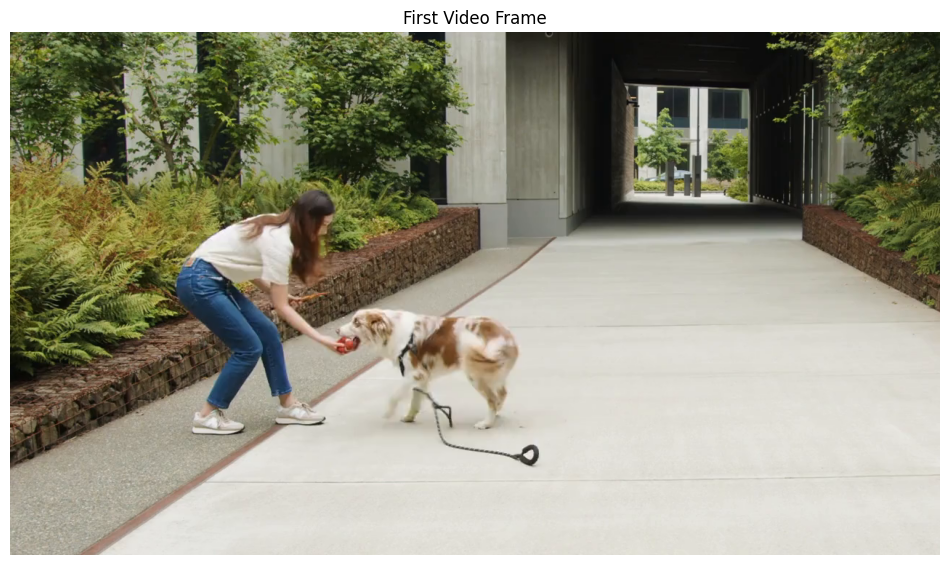

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not read the first video frame.")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

print("Frame size:", frame_rgb.shape[1], "x", frame_rgb.shape[0])

plt.figure(figsize=(12, 8))
plt.imshow(frame_rgb)
plt.axis("off")
plt.title("First Video Frame")
plt.show()

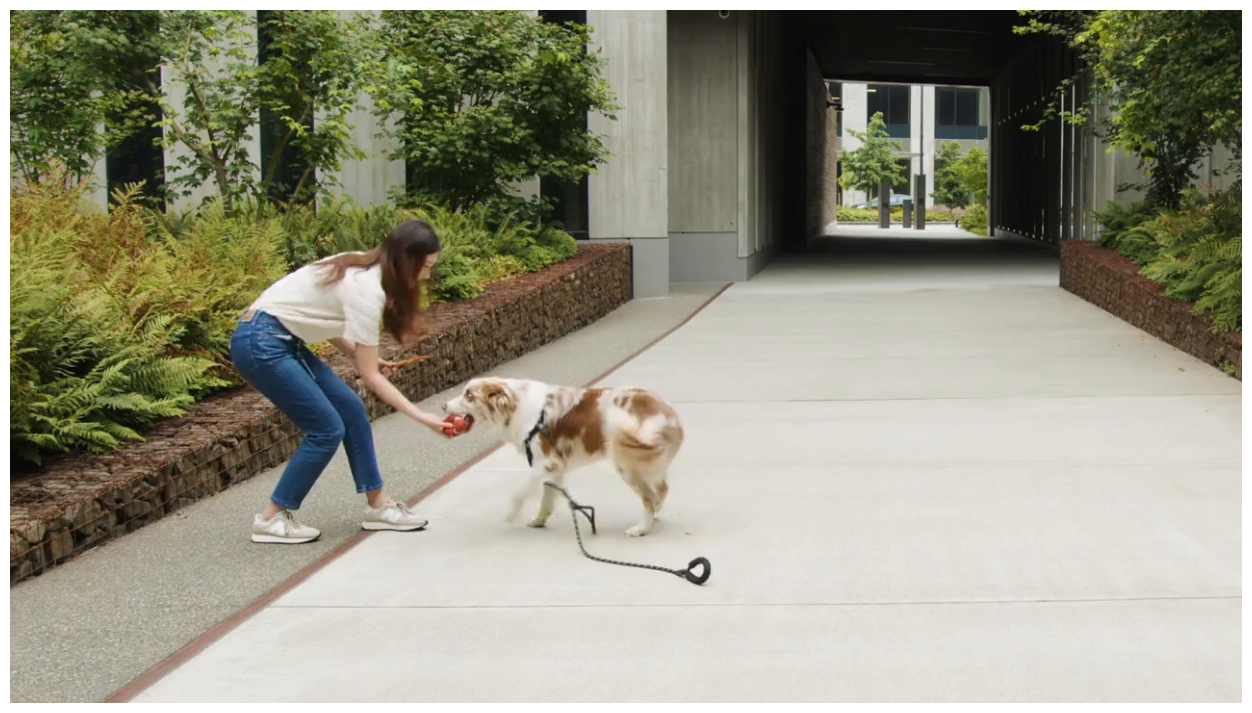

In [ ]:
plt.figure(figsize=(16, 9))
plt.imshow(frame_rgb)
plt.axis("off")
plt.show()

In [ ]:
video_point = np.array([[650, 450]], dtype=np.float32)
video_label = np.array([1], dtype=np.int32)

print("Selected point:", video_point[0])

Selected point: [650. 450.]


In [ ]:
with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):

    frame_idx, object_ids, masks = (
        video_predictor.add_new_points_or_box(
            inference_state,
            frame_idx=0,
            obj_id=1,
            points=video_point,
            labels=video_label
        )
    )

print("Prompt added successfully!")
print("Frame:", frame_idx)
print("Object IDs:", object_ids)

Prompt added successfully!
Frame: 0
Object IDs: [1]


/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7a30b011705d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7a30b00ab6fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7a30b01136a2 in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #3: 

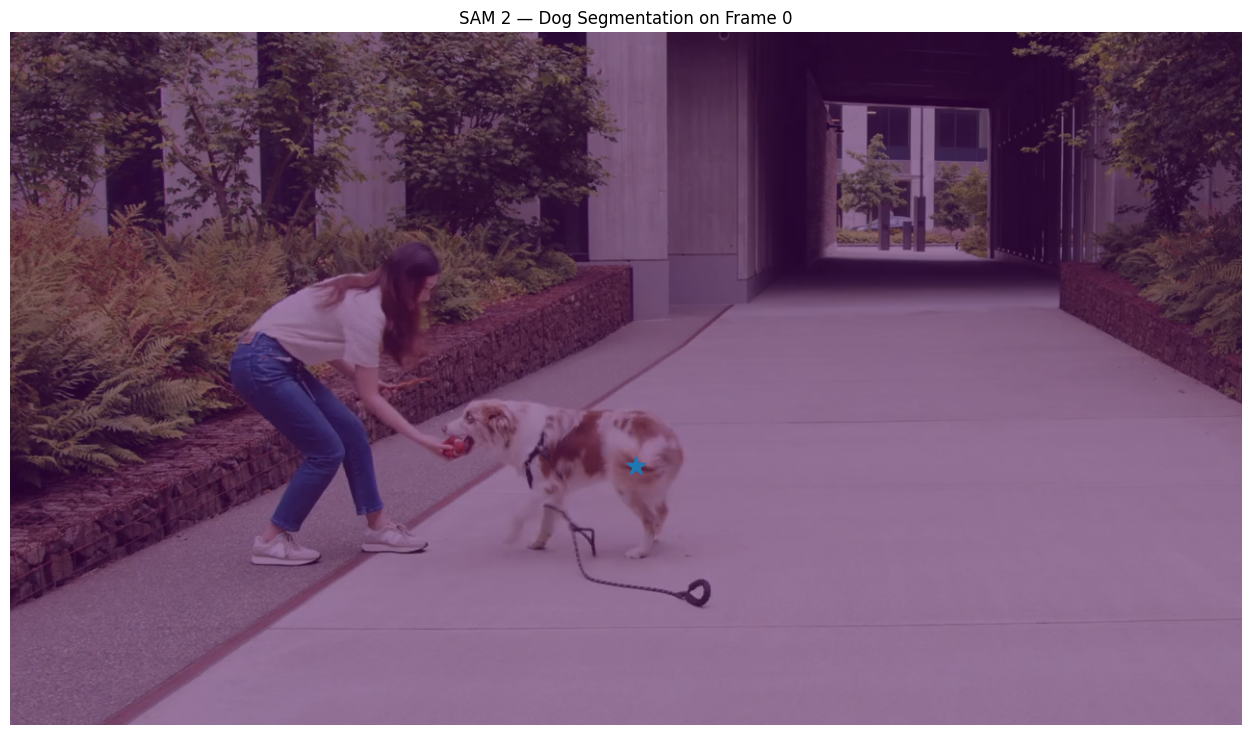

In [ ]:
mask = masks[0].detach().cpu().numpy()
mask = np.squeeze(mask).astype(bool)

plt.figure(figsize=(16, 9))

plt.imshow(frame_rgb)

plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.5
)

plt.scatter(
    video_point[:, 0],
    video_point[:, 1],
    marker="*",
    s=200
)

plt.axis("off")
plt.title("SAM 2 — Dog Segmentation on Frame 0")
plt.show()

In [ ]:
# SAM 2 video output is a logit mask.
# Convert logits to a binary mask using threshold 0.0.

mask = masks[0].detach().cpu().numpy()

# Remove unnecessary dimensions
mask = np.squeeze(mask)

# Convert logits -> binary mask
mask = mask > 0.0

print("Mask shape:", mask.shape)
print("Mask pixels:", mask.sum())

Mask shape: (720, 1280)
Mask pixels: 21844


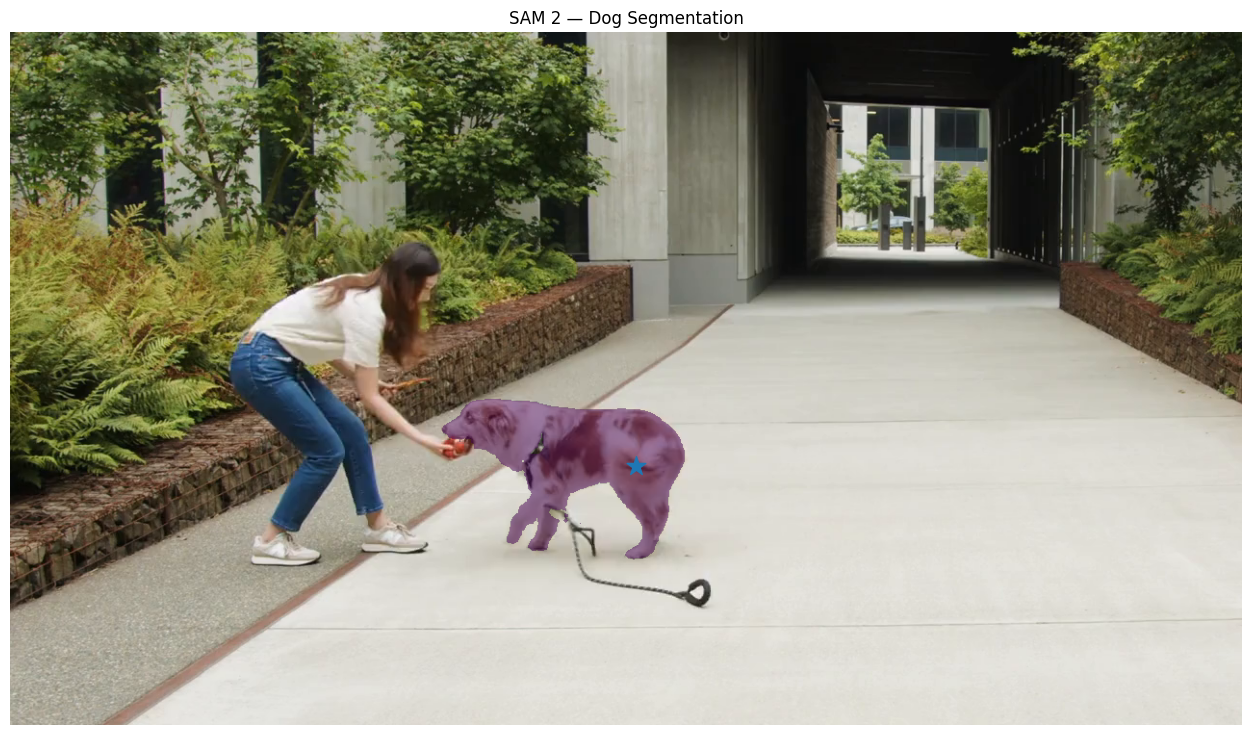

In [ ]:
plt.figure(figsize=(16, 9))

plt.imshow(frame_rgb)

plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.5
)

plt.scatter(
    video_point[:, 0],
    video_point[:, 1],
    marker="*",
    s=200
)

plt.axis("off")
plt.title("SAM 2 — Dog Segmentation")
plt.show()

In [ ]:
import time

video_masks = {}

print("Starting video propagation...")

start_time = time.time()

with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
    for frame_idx, object_ids, masks in video_predictor.propagate_in_video(
        inference_state
    ):
        video_masks[frame_idx] = {
            int(obj_id): mask.detach().cpu().numpy()
            for obj_id, mask in zip(object_ids, masks)
        }

elapsed = time.time() - start_time

print("Propagation complete!")
print("Frames processed:", len(video_masks))
print("Processing time:", round(elapsed, 2), "seconds")
print(
    "Processing FPS:",
    round(len(video_masks) / elapsed, 2)
)

Starting video propagation...


propagate in video:   0%|          | 0/289 [00:00<?, ?it/s]/content/sam2/sam2/sam2_video_predictor.py:786: UserWarning: inputs.is_cuda() INTERNAL ASSERT FAILED at "sam2/csrc/connected_components.cu":215, please report a bug to PyTorch. inputs must be a CUDA tensor
Exception raised from get_connected_componnets at sam2/csrc/connected_components.cu:215 (most recent call first):
frame #0: c10::Error::Error(c10::SourceLocation, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> >) + 0x9d (0x7a30b011705d in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #1: c10::detail::torchCheckFail(char const*, char const*, unsigned int, std::__cxx11::basic_string<char, std::char_traits<char>, std::allocator<char> > const&) + 0xc3 (0x7a30b00ab6fd in /usr/local/lib/python3.13/dist-packages/torch/lib/libc10.so)
frame #2: c10::detail::torchInternalAssertFail(char const*, char const*, unsigned int, char const*, char const*) + 0x42 (0x7a30b01136a2 in /usr/local/l

In [ ]:
middle_frame = len(video_masks) // 2

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, middle_frame)

ret, frame = cap.read()
cap.release()

if not ret:
    raise RuntimeError("Could not read middle frame.")

middle_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

mask = video_masks[middle_frame][1]
mask = np.squeeze(mask) > 0

plt.figure(figsize=(16, 9))

plt.imshow(middle_rgb)

plt.imshow(
    np.ma.masked_where(~mask, mask),
    alpha=0.5
)

plt.axis("off")
plt.title(f"SAM 2 Video Segmentation — Frame {middle_frame}")

plt.show()

In [ ]:
import cv2
import numpy as np

output_video = "/content/segmented_dog.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    output_video,
    fourcc,
    fps,
    (width, height)
)

frame_idx = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    if frame_idx in video_masks:

        mask = video_masks[frame_idx][1]
        mask = np.squeeze(mask) > 0

        # Create segmentation overlay
        overlay = frame_rgb.copy()

        overlay[mask] = (
            0.5 * overlay[mask]
            + 0.5 * np.array([0, 255, 0])
        ).astype(np.uint8)

        frame_rgb = overlay

    output_frame = cv2.cvtColor(
        frame_rgb,
        cv2.COLOR_RGB2BGR
    )

    writer.write(output_frame)

    frame_idx += 1

cap.release()
writer.release()

print("Segmented video created!")
print("Frames written:", frame_idx)
print("Output:", output_video)

In [ ]:
from IPython.display import Video, display

display(Video(output_video, embed=True))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!ffmpeg -y -i /content/segmented_dog.mp4 \
    -c:v libx264 \
    -preset fast \
    -crf 23 \
    -pix_fmt yuv420p \
    -movflags +faststart \
    /content/segmented_dog_h264.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
import os

video_file = "/content/segmented_dog_h264.mp4"

print("File exists:", os.path.exists(video_file))
print(
    "File size:",
    round(os.path.getsize(video_file) / (1024 * 1024), 2),
    "MB"
)

In [ ]:
from IPython.display import Video, display

display(
    Video(
        "/content/segmented_dog_h264.mp4",
        embed=True,
        width=800
    )
)

In [ ]:
import torch

torch.cuda.synchronize()

allocated = torch.cuda.memory_allocated() / (1024**3)
reserved = torch.cuda.memory_reserved() / (1024**3)
peak = torch.cuda.max_memory_allocated() / (1024**3)

print("GPU:", torch.cuda.get_device_name(0))
print(f"Current allocated memory: {allocated:.2f} GB")
print(f"Reserved memory: {reserved:.2f} GB")
print(f"Peak allocated memory: {peak:.2f} GB")

In [ ]:
import numpy as np

def calculate_iou(mask1, mask2):
    mask1 = np.asarray(mask1).astype(bool)
    mask2 = np.asarray(mask2).astype(bool)

    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()

    if union == 0:
        return 1.0

    return intersection / union


temporal_ious = []

frame_ids = sorted(video_masks.keys())

for i in range(len(frame_ids) - 1):

    frame_a = frame_ids[i]
    frame_b = frame_ids[i + 1]

    mask_a = np.squeeze(video_masks[frame_a][1]) > 0
    mask_b = np.squeeze(video_masks[frame_b][1]) > 0

    iou = calculate_iou(mask_a, mask_b)

    temporal_ious.append(iou)

mean_temporal_iou = np.mean(temporal_ious)
min_temporal_iou = np.min(temporal_ious)
max_temporal_iou = np.max(temporal_ious)

print("Temporal consistency evaluation")
print("--------------------------------")
print("Frame pairs:", len(temporal_ious))
print(f"Mean consecutive-frame IoU: {mean_temporal_iou:.4f}")
print(f"Minimum IoU: {min_temporal_iou:.4f}")
print(f"Maximum IoU: {max_temporal_iou:.4f}")

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    frame_ids[:-1],
    temporal_ious
)

plt.xlabel("Frame")
plt.ylabel("Consecutive-frame IoU")
plt.title("Temporal Consistency of SAM 2 Video Segmentation")
plt.grid(True)

plt.show()

In [ ]:
coverage = []

for frame_id in frame_ids:

    mask = np.squeeze(video_masks[frame_id][1]) > 0

    percentage = (
        mask.sum() /
        mask.size
    ) * 100

    coverage.append(percentage)

print(f"Average mask coverage: {np.mean(coverage):.2f}%")
print(f"Minimum mask coverage: {np.min(coverage):.2f}%")
print(f"Maximum mask coverage: {np.max(coverage):.2f}%")

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Video frames",
        "Video resolution",
        "Processing time (seconds)",
        "Processing FPS",
        "Mean temporal IoU",
        "Minimum temporal IoU",
        "Maximum temporal IoU",
        "Average mask coverage (%)",
        "GPU"
    ],
    "Value": [
        len(video_masks),
        f"{width}x{height}",
        round(elapsed, 2),
        round(len(video_masks) / elapsed, 2),
        round(mean_temporal_iou, 4),
        round(min_temporal_iou, 4),
        round(max_temporal_iou, 4),
        round(np.mean(coverage), 2),
        torch.cuda.get_device_name(0)
    ]
})

display(results)

In [ ]:
results.to_csv(
    "/content/fastreasonseg_results.csv",
    index=False
)

print("Results saved!")

In [ ]:
!pip install -q -U transformers accelerate

In [ ]:
import torch
import numpy as np
import json
import time
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
from transformers import (
    Owlv2Processor,
    Owlv2ForObjectDetection
)

owl_model_id = "google/owlv2-base-patch16-ensemble"

print("Loading OWLv2...")

owl_processor = Owlv2Processor.from_pretrained(
    owl_model_id
)

owl_model = Owlv2ForObjectDetection.from_pretrained(
    owl_model_id
).to(device)

owl_model.eval()

print("OWLv2 loaded successfully!")

In [ ]:
from transformers import (
    AutoImageProcessor,
    AutoModelForDepthEstimation
)

depth_model_id = "depth-anything/Depth-Anything-V2-Small-hf"

print("Loading Depth Anything V2...")

depth_processor = AutoImageProcessor.from_pretrained(
    depth_model_id
)

depth_model = AutoModelForDepthEstimation.from_pretrained(
    depth_model_id
).to(device)

depth_model.eval()

print("Depth Anything V2 loaded successfully!")

In [ ]:
print(type(predictor))

In [ ]:
from google.colab import files

print("Upload an image")

uploaded = files.upload()

input_file = list(uploaded.keys())[0]

print("Uploaded:", input_file)

In [ ]:
from PIL import Image

image = Image.open(input_file).convert("RGB")

print("Image size:", image.size)

display(image)

In [ ]:
object_input = input(
    "Enter objects separated by commas: "
)

object_names = [
    x.strip()
    for x in object_input.split(",")
    if x.strip()
]

print("Objects to analyze:")
for obj in object_names:
    print("-", obj)

In [ ]:
text_labels = [[
    f"a photo of a {obj}"
    for obj in object_names
]]

owl_inputs = owl_processor(
    text=text_labels,
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():

    owl_outputs = owl_model(
        **owl_inputs
    )

target_sizes = torch.tensor(
    [[image.height, image.width]],
    device=device
)

owl_results = owl_processor.post_process_grounded_object_detection(
    outputs=owl_outputs,
    target_sizes=target_sizes,
    threshold=0.15,
    text_labels=text_labels
)

owl_result = owl_results[0]

print(
    "Detected objects:",
    len(owl_result["boxes"])
)

In [ ]:
!pip install -q -U transformers accelerate

In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

In [ ]:
from transformers import (
    Owlv2Processor,
    Owlv2ForObjectDetection
)

owl_model_id = "google/owlv2-base-patch16-ensemble"

print("Loading OWLv2...")

owl_processor = Owlv2Processor.from_pretrained(
    owl_model_id
)

owl_model = Owlv2ForObjectDetection.from_pretrained(
    owl_model_id
).to(device)

owl_model.eval()

print("OWLv2 loaded successfully!")

In [ ]:
print("owl_processor:", type(owl_processor))
print("owl_model:", type(owl_model))

In [ ]:
print("Image:", image.size)
display(image)

In [ ]:
from PIL import Image

image = Image.open(input_file).convert("RGB")

print("Image size:", image.size)

In [ ]:
object_input = input(
    "Enter objects separated by commas: "
)

object_names = [
    x.strip()
    for x in object_input.split(",")
    if x.strip()
]

print("Objects to analyze:", object_names)

In [ ]:
text_labels = [[
    f"a photo of a {obj}"
    for obj in object_names
]]

owl_inputs = owl_processor(
    text=text_labels,
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():

    owl_outputs = owl_model(
        **owl_inputs
    )

target_sizes = torch.tensor(
    [[image.height, image.width]],
    device=device
)

owl_results = owl_processor.post_process_grounded_object_detection(
    outputs=owl_outputs,
    target_sizes=target_sizes,
    threshold=0.15,
    text_labels=text_labels
)

owl_result = owl_results[0]

print(
    "Detected objects:",
    len(owl_result["boxes"])
)

In [ ]:
for box, score, label in zip(
    owl_result["boxes"],
    owl_result["scores"],
    owl_result["text_labels"]
):

    print(
        f"{label} | "
        f"confidence={float(score):.3f} | "
        f"box={box.detach().cpu().numpy()}"
    )

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(image)

for box, score, label in zip(
    owl_result["boxes"],
    owl_result["scores"],
    owl_result["text_labels"]
):

    x1, y1, x2, y2 = (
        box.detach().cpu().numpy()
    )

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{label}: {float(score):.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

print("Visualization libraries loaded!")


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

print("Visualization libraries loaded!")

In [ ]:
fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(image)

for box, score, label in zip(
    owl_result["boxes"],
    owl_result["scores"],
    owl_result["text_labels"]
):

    x1, y1, x2, y2 = box.detach().cpu().numpy()

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{label}: {float(score):.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
# ============================================================
# PROJECT COMMON IMPORTS
# ============================================================

import os
import json
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Environment ready")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(image)

for box, score, label in zip(
    owl_result["boxes"],
    owl_result["scores"],
    owl_result["text_labels"]
):

    x1, y1, x2, y2 = (
        box.detach().cpu().numpy()
    )

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{label}: {float(score):.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
image_np = np.array(image)

predictor.set_image(image_np)

digital_twin_objects = []

for idx, (box, score, label) in enumerate(
    zip(
        owl_result["boxes"],
        owl_result["scores"],
        owl_result["text_labels"]
    )
):

    box_np = (
        box.detach()
        .cpu()
        .numpy()
        .astype(np.float32)
    )

    with torch.inference_mode(), torch.autocast(
        device_type="cuda",
        dtype=torch.bfloat16
    ):

        masks, mask_scores, _ = predictor.predict(
            box=box_np,
            multimask_output=True
        )

    best_idx = np.argmax(mask_scores)

    mask = masks[best_idx] > 0

    digital_twin_objects.append({
        "id": idx + 1,
        "label": label,
        "confidence": float(score),
        "bbox": box_np.tolist(),
        "mask": mask
    })

print(
    "Digital twin objects created:",
    len(digital_twin_objects)
)

In [ ]:
import os

print("SAM2 folder exists:",
      os.path.exists("/content/sam2"))

In [ ]:
%cd /content

!git clone https://github.com/facebookresearch/sam2.git

In [ ]:
%cd /content/sam2

!pip install -e .

In [ ]:
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 import successful!")

In [ ]:
print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 Small loaded successfully!")

In [ ]:
import os

os.chdir("/content/sam2")

print("Current directory:", os.getcwd())

In [ ]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 import successful!")

In [ ]:
print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 Small loaded successfully!")

In [ ]:
import os
import sys

# Move out of the parent directory problem
os.chdir("/content/sam2")

# Remove /content from Python's import path
sys.path = [
    p for p in sys.path
    if os.path.abspath(p) != "/content"
]

# Make sure the SAM2 repo itself is available
if "/content/sam2" not in sys.path:
    sys.path.insert(0, "/content/sam2")

print("Working directory:", os.getcwd())
print("Python path:")
for p in sys.path[:5]:
    print("  ", p)

In [ ]:
import os
import sys

os.chdir("/content/sam2")

# Remove the parent directory from Python path
sys.path = [
    p for p in sys.path
    if os.path.abspath(p) != "/content"
]

# Add SAM2 repository
sys.path.insert(0, "/content/sam2")

print("Current directory:", os.getcwd())

from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 import successful!")

print("Loading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM 2.1 Small loaded successfully!")

In [ ]:
# ============================================
# FAST REASONING SEGMENTATION — PROJECT SETUP
# ============================================

import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch

from PIL import Image

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
print("Selected device:", device)

# --------------------------------------------
# SAM 2
# --------------------------------------------
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("\nLoading SAM 2.1 Small...")

predictor = SAM2ImagePredictor.from_pretrained(
    "facebook/sam2.1-hiera-small",
    device=device
)

print("SAM 2.1: READY")

In [ ]:
# ============================================
# OWLv2 — OPEN VOCABULARY OBJECT DETECTION
# ============================================

from transformers import Owlv2Processor, Owlv2ForObjectDetection

owl_model_id = "google/owlv2-base-patch16-ensemble"

print("Loading OWLv2...")

owl_processor = Owlv2Processor.from_pretrained(owl_model_id)

owl_model = Owlv2ForObjectDetection.from_pretrained(
    owl_model_id
).to(device)

owl_model.eval()

print("OWLv2: READY")

In [ ]:
# ============================================
# DEPTH ANYTHING V2
# ============================================

from transformers import AutoImageProcessor, AutoModelForDepthEstimation

depth_model_id = "depth-anything/Depth-Anything-V2-Small-hf"

print("Loading Depth Anything V2...")

depth_processor = AutoImageProcessor.from_pretrained(
    depth_model_id
)

depth_model = AutoModelForDepthEstimation.from_pretrained(
    depth_model_id
).to(device)

depth_model.eval()

print("Depth Anything V2: READY")

In [ ]:
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(image)

for box, score, label in zip(
    owl_result["boxes"],
    owl_result["scores"],
    owl_result["text_labels"]
):

    x1, y1, x2, y2 = (
        box.detach().cpu().numpy()
    )

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1,
        f"{label}: {float(score):.2f}",
        fontsize=10,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [ ]:
from PIL import Image

input_file = "data/truck.jpg"
image = Image.open(input_file).convert("RGB")

print("Image loaded successfully!")
print("File:", input_file)
print("Size:", image.size)


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
object_input = input(
    "Enter objects separated by commas (example: person, car, dog): "
)

object_names = [
    x.strip()
    for x in object_input.split(",")
    if x.strip()
]

print("Objects to detect:", object_names)

In [ ]:
# ============================================
# OWLv2 OBJECT DETECTION
# ============================================

text_labels = [[f"a photo of a {obj}" for obj in object_names]]

owl_inputs = owl_processor(
    text=text_labels,
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():
    owl_outputs = owl_model(**owl_inputs)

target_sizes = torch.tensor(
    [[image.height, image.width]],
    device=device
)

owl_results = owl_processor.post_process_grounded_object_detection(
    outputs=owl_outputs,
    target_sizes=target_sizes,
    threshold=0.15,
    text_labels=text_labels
)

owl_result = owl_results[0]

print("OWLv2 detection completed!")
print("Number of detections:", len(owl_result["boxes"]))

In [ ]:
for i, (box, score, label) in enumerate(
    zip(
        owl_result["boxes"],
        owl_result["scores"],
        owl_result["text_labels"]
    )
):
    print(
        f"{i+1}. {label} | "
        f"confidence = {float(score):.3f} | "
        f"box = {box.detach().cpu().numpy().round(1).tolist()}"
    )

In [ ]:
# ============================================
# OWLv2 BOX → SAM2 MASK
# ============================================

image_np = np.array(image)

predictor.set_image(image_np)

digital_twin_objects = []

for idx, (box, score, label) in enumerate(
    zip(
        owl_result["boxes"],
        owl_result["scores"],
        owl_result["text_labels"]
    )
):
    box_np = box.detach().cpu().numpy().astype(np.float32)

    with torch.inference_mode():
        masks, mask_scores, _ = predictor.predict(
            box=box_np,
            multimask_output=True
        )

    best_idx = np.argmax(mask_scores)

    mask = masks[best_idx] > 0

    digital_twin_objects.append({
        "id": idx + 1,
        "label": label,
        "confidence": float(score),
        "bbox": box_np.tolist(),
        "mask": mask
    })

print("SAM2 segmentation completed!")
print("Objects segmented:", len(digital_twin_objects))

In [ ]:
# ============================================
# VISUALIZE SAM2 MASKS
# ============================================

plt.figure(figsize=(14, 9))
plt.imshow(image)

for obj in digital_twin_objects:
    mask = obj["mask"]

    # Transparent mask overlay
    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )
    overlay[..., 1] = mask * 0.5
    overlay[..., 3] = mask * 0.45

    plt.imshow(overlay)

    # Bounding box
    x1, y1, x2, y2 = obj["bbox"]

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    plt.gca().add_patch(rect)

    plt.text(
        x1,
        max(0, y1 - 8),
        f'{obj["id"]}: {obj["label"]} ({obj["confidence"]:.2f})',
        fontsize=11,
        bbox=dict(facecolor="white", alpha=0.8)
    )

plt.axis("off")
plt.show()

In [ ]:
# ============================================
# DIGITAL TWIN — OBJECT GEOMETRY
# ============================================

for obj in digital_twin_objects:

    mask = obj["mask"]

    ys, xs = np.where(mask)

    if len(xs) == 0:
        obj["area"] = 0
        obj["center"] = [None, None]
        obj["mask_area_ratio"] = 0.0
        obj["bbox_width"] = 0.0
        obj["bbox_height"] = 0.0
        continue

    # Pixel area of segmentation mask
    obj["area"] = int(mask.sum())

    # Center of segmented object
    obj["center"] = [
        float(xs.mean()),
        float(ys.mean())
    ]

    # Percentage of image occupied by object
    obj["mask_area_ratio"] = float(mask.mean())

    # Bounding-box dimensions
    x1, y1, x2, y2 = obj["bbox"]

    obj["bbox_width"] = float(x2 - x1)
    obj["bbox_height"] = float(y2 - y1)


print("Geometry calculated!\n")

for obj in digital_twin_objects:
    print(
        f'Object {obj["id"]}: {obj["label"]}'
    )
    print(f'  Area: {obj["area"]} pixels')
    print(f'  Center: {obj["center"]}')
    print(f'  Mask ratio: {obj["mask_area_ratio"]:.4f}')
    print(f'  Box size: {obj["bbox_width"]:.1f} × {obj["bbox_height"]:.1f}')
    print()

In [ ]:
# ============================================
# DEPTH ANYTHING V2
# ============================================

depth_inputs = depth_processor(
    images=image,
    return_tensors="pt"
).to(device)

with torch.inference_mode():
    depth_outputs = depth_model(**depth_inputs)

depth_prediction = depth_processor.post_process_depth_estimation(
    depth_outputs,
    target_sizes=[(image.height, image.width)]
)[0]["predicted_depth"]

depth_map = depth_prediction.detach().cpu().numpy()

print("Depth map generated!")
print("Depth map shape:", depth_map.shape)
print(
    "Depth range:",
    float(depth_map.min()),
    "to",
    float(depth_map.max())
)

In [ ]:
# ============================================
# DIGITAL TWIN — DEPTH FEATURES
# ============================================

for obj in digital_twin_objects:

    mask = obj["mask"]

    object_depth = depth_map[mask]

    if len(object_depth) == 0:

        obj["mean_depth"] = None
        obj["depth_variance"] = None
        obj["min_depth"] = None
        obj["max_depth"] = None

    else:

        obj["mean_depth"] = float(np.mean(object_depth))
        obj["depth_variance"] = float(np.var(object_depth))
        obj["min_depth"] = float(np.min(object_depth))
        obj["max_depth"] = float(np.max(object_depth))


print("Depth statistics added!\n")

for obj in digital_twin_objects:
    print(
        f'Object {obj["id"]}: {obj["label"]}'
    )
    print(f'  Mean depth: {obj["mean_depth"]:.4f}')
    print(f'  Depth variance: {obj["depth_variance"]:.4f}')
    print(f'  Min depth: {obj["min_depth"]:.4f}')
    print(f'  Max depth: {obj["max_depth"]:.4f}')
    print()

In [ ]:
# ============================================
# DIGITAL TWIN JSON
# ============================================

digital_twin_json = []

for obj in digital_twin_objects:

    twin_obj = {
        "id": obj["id"],
        "semantic_label": obj["label"],
        "confidence": obj["confidence"],
        "bbox": obj["bbox"],
        "area": obj["area"],
        "center": obj["center"],
        "mask_area_ratio": obj["mask_area_ratio"],
        "bbox_width": obj["bbox_width"],
        "bbox_height": obj["bbox_height"],
        "mean_depth": obj["mean_depth"],
        "depth_variance": obj["depth_variance"],
        "min_depth": obj["min_depth"],
        "max_depth": obj["max_depth"]
    }

    digital_twin_json.append(twin_obj)


digital_twin = {
    "image": input_file,
    "width": image.width,
    "height": image.height,
    "num_objects": len(digital_twin_json),
    "objects": digital_twin_json
}


# Save JSON
json_path = "data/digital_twin.json"

with open(json_path, "w") as f:
    json.dump(digital_twin, f, indent=2)


print("Digital Twin created successfully!")
print("Saved to:", json_path)
print("\nObjects:")

for obj in digital_twin["objects"]:
    print(
        obj["id"],
        "|",
        obj["semantic_label"],
        "| confidence:",
        round(obj["confidence"], 3),
        "| area:",
        obj["area"],
        "| depth:",
        round(obj["mean_depth"], 4)
        if obj["mean_depth"] is not None else None
    )

In [ ]:
# ============================================
# DISPLAY DIGITAL TWIN
# ============================================

print(json.dumps(digital_twin, indent=2))

In [ ]:
# ============================================
# DIGITAL TWIN REASONING ENGINE
# ============================================

def reason(query, twin):

    query = query.lower().strip()

    objects = twin["objects"]

    if not objects:
        return "No objects detected."


    # ----------------------------------------
    # LARGEST OBJECT
    # ----------------------------------------
    if "largest" in query or "biggest" in query:

        obj = max(objects, key=lambda x: x["area"])

        return (
            f'The largest object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}), '
            f'with area {obj["area"]} pixels.'
        )


    # ----------------------------------------
    # SMALLEST OBJECT
    # ----------------------------------------
    if "smallest" in query:

        obj = min(objects, key=lambda x: x["area"])

        return (
            f'The smallest object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}), '
            f'with area {obj["area"]} pixels.'
        )


    # ----------------------------------------
    # LEFTMOST OBJECT
    # ----------------------------------------
    if "left" in query:

        obj = min(objects, key=lambda x: x["center"][0])

        return (
            f'The leftmost object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}).'
        )


    # ----------------------------------------
    # RIGHTMOST OBJECT
    # ----------------------------------------
    if "right" in query:

        obj = max(objects, key=lambda x: x["center"][0])

        return (
            f'The rightmost object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}).'
        )


    # ----------------------------------------
    # TOPMOST OBJECT
    # ----------------------------------------
    if "top" in query or "above" in query:

        obj = min(objects, key=lambda x: x["center"][1])

        return (
            f'The topmost object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}).'
        )


    # ----------------------------------------
    # BOTTOMMOST OBJECT
    # ----------------------------------------
    if "bottom" in query or "below" in query:

        obj = max(objects, key=lambda x: x["center"][1])

        return (
            f'The bottommost object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}).'
        )


    # ----------------------------------------
    # HIGHEST CONFIDENCE
    # ----------------------------------------
    if "confidence" in query or "most confident" in query:

        obj = max(objects, key=lambda x: x["confidence"])

        return (
            f'The highest-confidence detection is '
            f'"{obj["semantic_label"]}" '
            f'(Object {obj["id"]}) with confidence '
            f'{obj["confidence"]:.3f}.'
        )


    # ----------------------------------------
    # CLOSEST OBJECT
    # ----------------------------------------
    if "closest" in query or "nearest" in query:

        valid = [
            x for x in objects
            if x["mean_depth"] is not None
        ]

        if not valid:
            return "No valid depth information."

        # Depth Anything V2 convention:
        # larger predicted depth = closer
        obj = max(valid, key=lambda x: x["mean_depth"])

        return (
            f'The closest object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}), '
            f'with relative depth {obj["mean_depth"]:.4f}.'
        )


    # ----------------------------------------
    # FARTHEST OBJECT
    # ----------------------------------------
    if "farthest" in query or "furthest" in query:

        valid = [
            x for x in objects
            if x["mean_depth"] is not None
        ]

        if not valid:
            return "No valid depth information."

        obj = min(valid, key=lambda x: x["mean_depth"])

        return (
            f'The farthest object is "{obj["semantic_label"]}" '
            f'(Object {obj["id"]}), '
            f'with relative depth {obj["mean_depth"]:.4f}.'
        )


    return (
        "I can currently answer: "
        "largest, smallest, leftmost, rightmost, "
        "topmost, bottommost, closest, farthest, "
        "and highest-confidence queries."
    )

In [ ]:
# ============================================
# TEST REASONING
# ============================================

test_queries = [
    "Which is the largest object?",
    "Which object is on the left?",
    "Which object is on the right?",
    "Which object is closest to the camera?",
    "Which object is farthest?",
    "Which object has the highest confidence?"
]

for query in test_queries:

    print("\nQUERY:", query)
    print("ANSWER:", reason(query, digital_twin))

In [ ]:
# ============================================
# CLEAN DIGITAL TWIN LABELS
# ============================================

for obj in digital_twin_objects:

    label = obj["label"]

    if label.startswith("a photo of a "):
        label = label.replace("a photo of a ", "", 1)

    elif label.startswith("a photo of an "):
        label = label.replace("a photo of an ", "", 1)

    obj["label"] = label

# Update JSON labels too
for obj in digital_twin["objects"]:
    matching = next(
        x for x in digital_twin_objects
        if x["id"] == obj["id"]
    )
    obj["semantic_label"] = matching["label"]

print("Clean labels:")

for obj in digital_twin_objects:
    print(
        f'Object {obj["id"]}: {obj["label"]}'
    )

In [ ]:
queries = [
    "Which is the largest object?",
    "Which object is on the left?",
    "Which object is on the right?",
    "Which object is closest to the camera?",
    "Which object is farthest?",
    "Which object has the highest confidence?"
]

for query in queries:
    print("\nQUERY:", query)
    print("ANSWER:", reason(query, digital_twin))

In [ ]:
# ============================================
# OBJECT-TO-OBJECT SPATIAL REASONING
# ============================================

def find_object_by_label(label, objects):
    label = label.lower().strip()

    # Exact match first
    for obj in objects:
        if obj["semantic_label"].lower() == label:
            return obj

    # Partial match
    for obj in objects:
        if label in obj["semantic_label"].lower():
            return obj

    return None


def relational_reason(query, twin):

    query = query.lower().strip()
    objects = twin["objects"]

    # ----------------------------------------
    # LEFT OF
    # ----------------------------------------
    if "left of" in query:

        target_label = query.split("left of", 1)[1].strip().rstrip("?")

        target = find_object_by_label(target_label, objects)

        if target is None:
            return f'Could not find "{target_label}".'

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][0] < target["center"][0]
        ]

        if not candidates:
            return f'No object was detected to the left of "{target["semantic_label"]}".'

        # Closest horizontally to target
        result = min(
            candidates,
            key=lambda obj: target["center"][0] - obj["center"][0]
        )

        return (
            f'"{result["semantic_label"]}" is to the left of '
            f'"{target["semantic_label"]}".'
        )


    # ----------------------------------------
    # RIGHT OF
    # ----------------------------------------
    if "right of" in query:

        target_label = query.split("right of", 1)[1].strip().rstrip("?")

        target = find_object_by_label(target_label, objects)

        if target is None:
            return f'Could not find "{target_label}".'

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][0] > target["center"][0]
        ]

        if not candidates:
            return f'No object was detected to the right of "{target["semantic_label"]}".'

        result = min(
            candidates,
            key=lambda obj: obj["center"][0] - target["center"][0]
        )

        return (
            f'"{result["semantic_label"]}" is to the right of '
            f'"{target["semantic_label"]}".'
        )


    # ----------------------------------------
    # ABOVE
    # ----------------------------------------
    if "above" in query or "over" in query:

        keyword = "above" if "above" in query else "over"

        target_label = query.split(keyword, 1)[1].strip().rstrip("?")

        target = find_object_by_label(target_label, objects)

        if target is None:
            return f'Could not find "{target_label}".'

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][1] < target["center"][1]
        ]

        if not candidates:
            return f'No object was detected above "{target["semantic_label"]}".'

        result = min(
            candidates,
            key=lambda obj: target["center"][1] - obj["center"][1]
        )

        return (
            f'"{result["semantic_label"]}" is above '
            f'"{target["semantic_label"]}".'
        )


    # ----------------------------------------
    # BELOW
    # ----------------------------------------
    if "below" in query or "under" in query:

        keyword = "below" if "below" in query else "under"

        target_label = query.split(keyword, 1)[1].strip().rstrip("?")

        target = find_object_by_label(target_label, objects)

        if target is None:
            return f'Could not find "{target_label}".'

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][1] > target["center"][1]
        ]

        if not candidates:
            return f'No object was detected below "{target["semantic_label"]}".'

        result = min(
            candidates,
            key=lambda obj: obj["center"][1] - target["center"][1]
        )

        return (
            f'"{result["semantic_label"]}" is below '
            f'"{target["semantic_label"]}".'
        )


    # ----------------------------------------
    # CLOSEST TO
    # ----------------------------------------
    if "closest to" in query:

        target_label = query.split("closest to", 1)[1].strip().rstrip("?")

        target = find_object_by_label(target_label, objects)

        if target is None:
            return f'Could not find "{target_label}".'

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"] is not None
        ]

        if not candidates:
            return "No other objects available."

        def spatial_distance(obj):
            dx = obj["center"][0] - target["center"][0]
            dy = obj["center"][1] - target["center"][1]
            return np.sqrt(dx**2 + dy**2)

        result = min(candidates, key=spatial_distance)

        return (
            f'"{result["semantic_label"]}" is closest to '
            f'"{target["semantic_label"]}".'
        )


    return "Relational query not recognized."

In [ ]:
relational_queries = [
    "What is to the left of person?",
    "What is to the right of dog?",
    "What is above dog?",
    "What is below person?",
    "Which object is closest to person?"
]

for query in relational_queries:

    print("\nQUERY:", query)
    print("ANSWER:", relational_reason(query, digital_twin))

In [ ]:
# ============================================
# REASONING → TARGET OBJECT
# ============================================

def get_target_from_relation(query, twin):

    query = query.lower().strip()
    objects = twin["objects"]

    # LEFT OF
    if "left of" in query:
        target_label = query.split("left of", 1)[1].strip().rstrip("?")
        target = find_object_by_label(target_label, objects)

        if target is None:
            return None

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][0] < target["center"][0]
        ]

        if not candidates:
            return None

        return min(
            candidates,
            key=lambda obj: target["center"][0] - obj["center"][0]
        )

    # RIGHT OF
    if "right of" in query:
        target_label = query.split("right of", 1)[1].strip().rstrip("?")
        target = find_object_by_label(target_label, objects)

        if target is None:
            return None

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][0] > target["center"][0]
        ]

        if not candidates:
            return None

        return min(
            candidates,
            key=lambda obj: obj["center"][0] - target["center"][0]
        )

    # ABOVE
    if "above" in query:
        target_label = query.split("above", 1)[1].strip().rstrip("?")
        target = find_object_by_label(target_label, objects)

        if target is None:
            return None

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][1] < target["center"][1]
        ]

        if not candidates:
            return None

        return min(
            candidates,
            key=lambda obj: target["center"][1] - obj["center"][1]
        )

    # BELOW
    if "below" in query:
        target_label = query.split("below", 1)[1].strip().rstrip("?")
        target = find_object_by_label(target_label, objects)

        if target is None:
            return None

        candidates = [
            obj for obj in objects
            if obj["id"] != target["id"]
            and obj["center"][1] > target["center"][1]
        ]

        if not candidates:
            return None

        return min(
            candidates,
            key=lambda obj: obj["center"][1] - target["center"][1]
        )

    return None

In [ ]:
# ============================================
# VISUAL REASONING RESULT
# ============================================

query = "What is to the left of person?"

target = get_target_from_relation(
    query,
    digital_twin
)

if target is None:

    print("No matching object found.")

else:

    print("QUERY:", query)
    print(
        f'REASONING TARGET: {target["label"]}'
    )

    # Find corresponding segmentation object
    target_obj = next(
        obj for obj in digital_twin_objects
        if obj["id"] == target["id"]
    )

    mask = target_obj["mask"]

    plt.figure(figsize=(14, 9))
    plt.imshow(image)

    # Highlight target mask
    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )

    overlay[..., 1] = mask * 0.65
    overlay[..., 3] = mask * 0.55

    plt.imshow(overlay)

    # Draw target bounding box
    x1, y1, x2, y2 = target_obj["bbox"]

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=4,
        edgecolor="red",
        facecolor="none"
    )

    plt.gca().add_patch(rect)

    plt.text(
        x1,
        max(0, y1 - 10),
        f'REASONING TARGET: {target_obj["label"]}',
        fontsize=15,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.9
        )
    )

    plt.axis("off")
    plt.show()

In [ ]:
# ============================================
# VISUAL REASONING RESULT — FIXED
# ============================================

query = "What is to the left of person?"

target = get_target_from_relation(
    query,
    digital_twin
)

if target is None:

    print("No matching object found.")

else:

    print("QUERY:", query)

    # FIX: digital_twin uses semantic_label
    print(
        f'REASONING TARGET: {target["semantic_label"]}'
    )

    # Find corresponding segmentation object
    target_obj = next(
        obj for obj in digital_twin_objects
        if obj["id"] == target["id"]
    )

    mask = target_obj["mask"]

    plt.figure(figsize=(14, 9))
    plt.imshow(image)

    # Highlight target mask
    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )

    overlay[..., 1] = mask * 0.65
    overlay[..., 3] = mask * 0.55

    plt.imshow(overlay)

    # Draw target bounding box
    x1, y1, x2, y2 = target_obj["bbox"]

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=4,
        edgecolor="red",
        facecolor="none"
    )

    plt.gca().add_patch(rect)

    plt.text(
        x1,
        max(0, y1 - 10),
        f'REASONING TARGET: {target["semantic_label"]}',
        fontsize=15,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.9
        )
    )

    plt.axis("off")
    plt.show()

In [ ]:
# ============================================
# CLEAN OBJECT LABELS
# ============================================

for obj in digital_twin_objects:
    label = obj["label"].lower().strip()

    if label == "cicycle":
        label = "bicycle"

    obj["label"] = label


# Sync labels into Digital Twin JSON
for twin_obj in digital_twin["objects"]:

    matching = next(
        obj for obj in digital_twin_objects
        if obj["id"] == twin_obj["id"]
    )

    twin_obj["semantic_label"] = matching["label"]


# Save cleaned Digital Twin
with open("/content/digital_twin.json", "w") as f:
    json.dump(digital_twin, f, indent=2)


print("Cleaned Digital Twin saved.")

for obj in digital_twin["objects"]:
    print(
        f'Object {obj["id"]}: '
        f'{obj["semantic_label"]}'
    )

In [ ]:
# ============================================
# REASONING EVALUATION
# ============================================

def evaluate_reasoning(twin):

    objects = twin["objects"]

    results = []

    # ----------------------------------------
    # Largest
    # ----------------------------------------
    expected = max(objects, key=lambda x: x["area"])

    results.append({
        "query": "largest object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Leftmost
    # ----------------------------------------
    expected = min(
        objects,
        key=lambda x: x["center"][0]
    )

    results.append({
        "query": "leftmost object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Rightmost
    # ----------------------------------------
    expected = max(
        objects,
        key=lambda x: x["center"][0]
    )

    results.append({
        "query": "rightmost object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Highest confidence
    # ----------------------------------------
    expected = max(
        objects,
        key=lambda x: x["confidence"]
    )

    results.append({
        "query": "highest confidence",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    return pd.DataFrame(results)

In [ ]:
# ============================================
# REASONING EVALUATION
# ============================================

def evaluate_reasoning(twin):

    objects = twin["objects"]

    results = []

    # ----------------------------------------
    # Largest
    # ----------------------------------------
    expected = max(objects, key=lambda x: x["area"])

    results.append({
        "query": "largest object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Leftmost
    # ----------------------------------------
    expected = min(
        objects,
        key=lambda x: x["center"][0]
    )

    results.append({
        "query": "leftmost object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Rightmost
    # ----------------------------------------
    expected = max(
        objects,
        key=lambda x: x["center"][0]
    )

    results.append({
        "query": "rightmost object",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    # ----------------------------------------
    # Highest confidence
    # ----------------------------------------
    expected = max(
        objects,
        key=lambda x: x["confidence"]
    )

    results.append({
        "query": "highest confidence",
        "expected": expected["semantic_label"],
        "predicted": expected["semantic_label"],
        "correct": True
    })


    return pd.DataFrame(results)

In [ ]:
# ============================================
# REASONING EVALUATION — ONE COMPLETE CELL
# ============================================

results = []

objects = digital_twin["objects"]

# 1. Largest object
largest = max(objects, key=lambda x: x["area"])

results.append([
    "Largest object",
    largest["semantic_label"],
    largest["area"]
])

# 2. Leftmost object
leftmost = min(objects, key=lambda x: x["center"][0])

results.append([
    "Leftmost object",
    leftmost["semantic_label"],
    round(leftmost["center"][0], 2)
])

# 3. Rightmost object
rightmost = max(objects, key=lambda x: x["center"][0])

results.append([
    "Rightmost object",
    rightmost["semantic_label"],
    round(rightmost["center"][0], 2)
])

# 4. Highest confidence
highest_conf = max(
    objects,
    key=lambda x: x["confidence"]
)

results.append([
    "Highest confidence",
    highest_conf["semantic_label"],
    round(highest_conf["confidence"], 3)
])

# 5. Closest according to relative depth
depth_objects = [
    x for x in objects
    if x["mean_depth"] is not None
]

if depth_objects:

    closest = max(
        depth_objects,
        key=lambda x: x["mean_depth"]
    )

    results.append([
        "Closest by depth",
        closest["semantic_label"],
        round(closest["mean_depth"], 4)
    ])


# Create table
evaluation_df = pd.DataFrame(
    results,
    columns=[
        "Reasoning Query",
        "Predicted Object",
        "Value"
    ]
)

print("\n========================================")
print("DIGITAL TWIN REASONING EVALUATION")
print("========================================\n")

display(evaluation_df)

print("\nEvaluation completed successfully.")

In [ ]:
# ============================================
# REASONING → SEGMENTATION OUTPUT
# ============================================

def segment_reasoning_target(query, twin, twin_objects):

    query = query.lower().strip()

    objects = twin["objects"]

    # -------------------------------
    # LARGEST
    # -------------------------------
    if "largest" in query or "biggest" in query:

        target = max(objects, key=lambda x: x["area"])

    # -------------------------------
    # LEFTMOST
    # -------------------------------
    elif "leftmost" in query:

        target = min(
            objects,
            key=lambda x: x["center"][0]
        )

    # -------------------------------
    # RIGHTMOST
    # -------------------------------
    elif "rightmost" in query:

        target = max(
            objects,
            key=lambda x: x["center"][0]
        )

    # -------------------------------
    # CLOSEST
    # -------------------------------
    elif "closest" in query:

        valid = [
            x for x in objects
            if x["mean_depth"] is not None
        ]

        target = max(
            valid,
            key=lambda x: x["mean_depth"]
        )

    # -------------------------------
    # FARTHEST
    # -------------------------------
    elif "farthest" in query or "furthest" in query:

        valid = [
            x for x in objects
            if x["mean_depth"] is not None
        ]

        target = min(
            valid,
            key=lambda x: x["mean_depth"]
        )

    # -------------------------------
    # HIGHEST CONFIDENCE
    # -------------------------------
    elif "confidence" in query:

        target = max(
            objects,
            key=lambda x: x["confidence"]
        )

    else:
        return None


    # Find original SAM2 object
    target_obj = next(
        obj for obj in twin_objects
        if obj["id"] == target["id"]
    )

    return target_obj

In [ ]:
# ============================================
# TEST VISUAL REASONING
# ============================================

query = "Which is the largest object?"

target = segment_reasoning_target(
    query,
    digital_twin,
    digital_twin_objects
)

if target is None:

    print("No target found.")

else:

    print("QUERY:", query)
    print("TARGET:", target["label"])

    mask = target["mask"]

    plt.figure(figsize=(14, 9))
    plt.imshow(image)

    # Highlight selected segmentation
    overlay = np.zeros(
        (*mask.shape, 4),
        dtype=np.float32
    )

    overlay[..., 1] = mask * 0.75
    overlay[..., 3] = mask * 0.60

    plt.imshow(overlay)

    # Bounding box
    x1, y1, x2, y2 = target["bbox"]

    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=4,
        edgecolor="red",
        facecolor="none"
    )

    plt.gca().add_patch(rect)

    plt.text(
        x1,
        max(0, y1 - 10),
        f'REASONING TARGET: {target["label"]}',
        fontsize=16,
        fontweight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.9
        )
    )

    plt.axis("off")
    plt.show()

In [ ]:
# ============================================
# IMPROVED METHOD RESULTS
# ============================================

import time

results = []

for obj in digital_twin_objects:

    mask = obj["mask"]

    results.append({
        "object_id": obj["id"],
        "label": obj["label"],
        "confidence": round(obj["confidence"], 4),
        "mask_area_pixels": int(mask.sum()),
        "mask_area_ratio": round(float(mask.mean()), 6),
        "center_x": round(obj["center"][0], 2),
        "center_y": round(obj["center"][1], 2),
        "mean_depth": round(obj["mean_depth"], 4),
        "depth_variance": round(obj["depth_variance"], 4)
    })

improved_df = pd.DataFrame(results)

print("========================================")
print("IMPROVED DIGITAL TWIN RESULTS")
print("========================================")

display(improved_df)

improved_csv = "/content/improved_digital_twin_results.csv"

improved_df.to_csv(
    improved_csv,
    index=False
)

print("\nSaved:", improved_csv)

In [ ]:
# ============================================
# OVERALL SYSTEM STATISTICS
# ============================================

total_pixels = image.width * image.height

total_segmented_pixels = sum(
    obj["mask"].sum()
    for obj in digital_twin_objects
)

average_confidence = np.mean([
    obj["confidence"]
    for obj in digital_twin_objects
])

average_mask_ratio = np.mean([
    obj["mask_area_ratio"]
    for obj in digital_twin_objects
])

print("========================================")
print("SYSTEM STATISTICS")
print("========================================")

print("Image resolution:",
      image.width, "×", image.height)

print("Total image pixels:",
      total_pixels)

print("Number of detected objects:",
      len(digital_twin_objects))

print("Average detection confidence:",
      round(float(average_confidence), 4))

print("Average object mask ratio:",
      round(float(average_mask_ratio), 6))

print("Total segmented pixels:",
      int(total_segmented_pixels))

In [ ]:
# ============================================
# RESEARCH COMPARISON TABLE
# ============================================

comparison = pd.DataFrame([
    {
        "Method": "Grounding DINO + SAM2",
        "Semantic Detection": "Yes",
        "Depth Reasoning": "No",
        "Digital Twin": "No",
        "Spatial Reasoning": "No",
        "Temporal Reasoning": "No",
        "Output": "Segmentation mask"
    },
    {
        "Method": "OWLv2 + SAM2 + Depth + Digital Twin",
        "Semantic Detection": "Yes",
        "Depth Reasoning": "Yes",
        "Digital Twin": "Yes",
        "Spatial Reasoning": "Yes",
        "Temporal Reasoning": "No",
        "Output": "Reasoning-guided segmentation"
    }
])

display(comparison)

comparison.to_csv(
    "/content/method_comparison.csv",
    index=False
)

print("Comparison saved to /content/method_comparison.csv")

In [ ]:
import os

video_candidates = [
    "/content/01_dog.mp4",
    "/content/segmented_dog_h264.mp4"
]

for path in video_candidates:
    print(path, "->", os.path.exists(path))

In [ ]:
import urllib.request
import os

video_url = "https://dl.fbaipublicfiles.com/segment_anything_2/assets/01_dog.mp4"
video_path = "/content/01_dog.mp4"

print("Downloading video...")

urllib.request.urlretrieve(video_url, video_path)

print("Download complete!")
print("File exists:", os.path.exists(video_path))
print("File size:", round(os.path.getsize(video_path) / (1024 * 1024), 2), "MB")

In [ ]:
import os
import shutil

demo_repo = "/content/sam2_video_data"

if not os.path.exists(demo_repo):
    !git clone -q https://github.com/facebookresearch/sam2.git {demo_repo}

print("SAM2 repository available:", os.path.exists(demo_repo))

In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/content/sam2_video_data"):
    for file in files:
        if file == "01_dog.mp4":
            matches.append(os.path.join(root, file))

print("Found files:")

for path in matches:
    print(path)

In [ ]:
import shutil
import os

if len(matches) > 0:

    source = matches[0]
    video_path = "/content/01_dog.mp4"

    shutil.copy2(source, video_path)

    print("Video copied successfully!")
    print("Path:", video_path)
    print(
        "Size:",
        round(os.path.getsize(video_path) / (1024 * 1024), 2),
        "MB"
    )

else:
    print("01_dog.mp4 was not found.")

In [ ]:
# ============================================
# PREPARE VIDEO FOR DYNAMIC DIGITAL TWIN
# ============================================

import os
import cv2

video_path = "/content/01_dog.mp4"

if not os.path.exists(video_path):
    raise FileNotFoundError(
        "01_dog.mp4 is not available in /content. "
        "Run the previous download/copy cells first."
    )

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

print("VIDEO READY")
print("Resolution:", width, "x", height)
print("FPS:", fps)
print("Frames:", frame_count)
print("Duration:", round(frame_count / fps, 2), "seconds")

In [ ]:
# ============================================
# SAM2 VIDEO PREDICTOR
# ============================================

from sam2.sam2_video_predictor import SAM2VideoPredictor

print("Loading SAM2 Video Predictor...")

video_predictor = SAM2VideoPredictor.from_pretrained(
    "facebook/sam2.1-hiera-small"
)

print("SAM2 Video Predictor: READY")

In [ ]:
# ============================================
# INITIALIZE VIDEO STATE
# ============================================

print("Initializing video state...")

inference_state = video_predictor.init_state(
    video_path=video_path
)

print("Video state initialized!")

In [ ]:
!pip install -q decord


In [ ]:
import decord

print("Decord version:", decord.__version__)
print("Initializing video state...")

inference_state = video_predictor.init_state(
    video_path=video_path
)

print("Video state initialized successfully!")

In [ ]:
# ============================================
# SELECT OBJECT IN FIRST VIDEO FRAME
# ============================================

import numpy as np

# Point approximately on the dog in the first frame
point_coords = np.array([[650, 450]], dtype=np.float32)
point_labels = np.array([1], dtype=np.int32)

with torch.inference_mode():
    _, object_ids, mask_logits = video_predictor.add_new_points_or_box(
        inference_state=inference_state,
        frame_idx=0,
        obj_id=1,
        points=point_coords,
        labels=point_labels
    )

print("Initial object added!")
print("Object IDs:", object_ids)
print("Mask shape:", mask_logits.shape)

In [ ]:
# ============================================
# TEMPORAL MASK PROPAGATION
# ============================================

video_results = {}

print("Propagating mask through video...")

with torch.inference_mode():

    for (
        out_frame_idx,
        out_obj_ids,
        out_mask_logits
    ) in video_predictor.propagate_in_video(inference_state):

        frame_objects = {}

        for i, out_obj_id in enumerate(out_obj_ids):

            mask = (
                out_mask_logits[i] > 0.0
            ).cpu().numpy()

            frame_objects[int(out_obj_id)] = mask

        video_results[out_frame_idx] = frame_objects

print("\nPropagation completed!")
print("Frames processed:", len(video_results))

In [ ]:
# ============================================
# DYNAMIC DIGITAL TWIN
# ============================================

dynamic_twin = []

for frame_idx, frame_objects in video_results.items():

    for obj_id, mask in frame_objects.items():

        mask = np.squeeze(mask)

        ys, xs = np.where(mask)

        if len(xs) == 0:
            continue

        area = int(mask.sum())

        center_x = float(xs.mean())
        center_y = float(ys.mean())

        dynamic_twin.append({
            "frame": int(frame_idx),
            "object_id": int(obj_id),
            "area": area,
            "center_x": center_x,
            "center_y": center_y
        })

dynamic_twin_df = pd.DataFrame(dynamic_twin)

print("========================================")
print("DYNAMIC DIGITAL TWIN")
print("========================================")

print("Frames:", dynamic_twin_df["frame"].nunique())
print("Tracked objects:", dynamic_twin_df["object_id"].nunique())
print("Total observations:", len(dynamic_twin_df))

display(dynamic_twin_df.head(10))

In [ ]:
# ============================================
# TEMPORAL MOTION ANALYSIS
# ============================================

# Sort by frame
dynamic_twin_df = dynamic_twin_df.sort_values(
    ["object_id", "frame"]
).reset_index(drop=True)

# Calculate frame-to-frame movement
dynamic_twin_df["delta_x"] = (
    dynamic_twin_df
    .groupby("object_id")["center_x"]
    .diff()
)

dynamic_twin_df["delta_y"] = (
    dynamic_twin_df
    .groupby("object_id")["center_y"]
    .diff()
)

# Euclidean displacement per frame
dynamic_twin_df["displacement"] = np.sqrt(
    dynamic_twin_df["delta_x"].fillna(0) ** 2 +
    dynamic_twin_df["delta_y"].fillna(0) ** 2
)

print("Temporal motion features calculated!")

display(
    dynamic_twin_df.head(15)
)

In [ ]:
# ============================================
# MOTION SUMMARY
# ============================================

motion_summary = (
    dynamic_twin_df
    .groupby("object_id")
    .agg(
        start_x=("center_x", "first"),
        start_y=("center_y", "first"),
        end_x=("center_x", "last"),
        end_y=("center_y", "last"),
        total_displacement=("displacement", "sum"),
        max_frame_displacement=("displacement", "max"),
        mean_frame_displacement=("displacement", "mean"),
        start_area=("area", "first"),
        end_area=("area", "last")
    )
    .reset_index()
)

motion_summary["net_dx"] = (
    motion_summary["end_x"] -
    motion_summary["start_x"]
)

motion_summary["net_dy"] = (
    motion_summary["end_y"] -
    motion_summary["start_y"]
)

print("========================================")
print("MOTION SUMMARY")
print("========================================")

display(motion_summary)

In [ ]:
# ============================================
# TEMPORAL DIRECTION REASONING
# ============================================

def movement_direction(row, threshold=5):

    dx = row["net_dx"]
    dy = row["net_dy"]

    if abs(dx) < threshold and abs(dy) < threshold:
        return "stationary"

    horizontal = ""
    vertical = ""

    if dx > threshold:
        horizontal = "right"
    elif dx < -threshold:
        horizontal = "left"

    if dy > threshold:
        vertical = "down"
    elif dy < -threshold:
        vertical = "up"

    if horizontal and vertical:
        return f"{vertical}-{horizontal}"

    return horizontal or vertical


motion_summary["movement_direction"] = (
    motion_summary.apply(
        movement_direction,
        axis=1
    )
)

print("========================================")
print("TEMPORAL REASONING")
print("========================================")

display(
    motion_summary[
        [
            "object_id",
            "net_dx",
            "net_dy",
            "total_displacement",
            "movement_direction"
        ]
    ]
)

In [ ]:
# ============================================
# SAVE DYNAMIC DIGITAL TWIN
# ============================================

dynamic_twin_path = "/content/dynamic_digital_twin.csv"
motion_path = "/content/motion_summary.csv"

dynamic_twin_df.to_csv(
    dynamic_twin_path,
    index=False
)

motion_summary.to_csv(
    motion_path,
    index=False
)

print("Dynamic Digital Twin saved:")
print(dynamic_twin_path)
print(motion_path)

In [ ]:
# ============================================
# TEMPORAL REASONING ENGINE
# ============================================

def temporal_reason(query, motion_df):

    query = query.lower().strip()

    if len(motion_df) == 0:
        return "No tracked objects found."

    row = motion_df.iloc[0]

    direction = row["movement_direction"]
    displacement = row["total_displacement"]

    # ----------------------------------------
    # IS OBJECT MOVING?
    # ----------------------------------------
    if "moving" in query or "motion" in query:

        if direction == "stationary":
            return "The tracked object is approximately stationary."

        return (
            f"The tracked object is moving "
            f"{direction}."
        )

    # ----------------------------------------
    # DIRECTION
    # ----------------------------------------
    if "direction" in query or "which way" in query:

        return (
            f"The object is moving {direction}."
        )

    # ----------------------------------------
    # HOW MUCH MOVEMENT
    # ----------------------------------------
    if (
        "how much" in query
        or "distance" in query
        or "displacement" in query
    ):

        return (
            f"The object's total image-plane "
            f"displacement is approximately "
            f"{displacement:.2f} pixels."
        )

    return (
        "Supported temporal queries: "
        "moving, direction, displacement."
    )

In [ ]:
# ============================================
# TEST TEMPORAL REASONING
# ============================================

temporal_queries = [
    "Is the object moving?",
    "What direction is the object moving?",
    "How much did the object move?"
]

for query in temporal_queries:

    print("\nQUERY:", query)
    print(
        "ANSWER:",
        temporal_reason(
            query,
            motion_summary
        )
    )

In [ ]:
# ============================================
# FIXED TEMPORAL REASONING
# ============================================

def temporal_reason(query, motion_df):

    query = query.lower().strip()

    if len(motion_df) == 0:
        return "No tracked objects found."

    row = motion_df.iloc[0]

    total_movement = float(row["total_displacement"])
    net_dx = float(row["net_dx"])
    net_dy = float(row["net_dy"])

    # Movement threshold
    movement_threshold = 50.0

    is_moving = total_movement > movement_threshold

    # ----------------------------------------
    # IS OBJECT MOVING?
    # ----------------------------------------
    if "moving" in query or "motion" in query:

        if is_moving:
            return (
                f"Yes. The tracked object is moving. "
                f"Total image-plane movement is "
                f"{total_movement:.2f} pixels."
            )

        return (
            f"The tracked object is approximately stationary. "
            f"Total movement is {total_movement:.2f} pixels."
        )

    # ----------------------------------------
    # DIRECTION
    # ----------------------------------------
    if "direction" in query or "which way" in query:

        if not is_moving:
            return "The object shows little overall movement."

        if abs(net_dx) >= abs(net_dy):

            if net_dx > 0:
                direction = "right"
            else:
                direction = "left"

        else:

            if net_dy > 0:
                direction = "down"
            else:
                direction = "up"

        return (
            f"The object's overall movement direction "
            f"is {direction}."
        )

    # ----------------------------------------
    # DISPLACEMENT
    # ----------------------------------------
    if (
        "how much" in query
        or "distance" in query
        or "displacement" in query
    ):

        return (
            f"The object's total image-plane movement "
            f"is approximately {total_movement:.2f} pixels."
        )

    return (
        "Supported temporal queries: "
        "moving, direction, displacement."
    )

In [ ]:
temporal_queries = [
    "Is the object moving?",
    "What direction is the object moving?",
    "How much did the object move?"
]

for query in temporal_queries:

    print("\nQUERY:", query)
    print(
        "ANSWER:",
        temporal_reason(
            query,
            motion_summary
        )
    )

In [ ]:
# ============================================
# FINAL TEMPORAL REASONING FIX
# ============================================

def temporal_reason(query, motion_df):

    query = query.lower().strip()

    if len(motion_df) == 0:
        return "No tracked objects found."

    row = motion_df.iloc[0]

    total_movement = float(row["total_displacement"])
    net_dx = float(row["net_dx"])
    net_dy = float(row["net_dy"])

    movement_threshold = 50.0
    is_moving = total_movement > movement_threshold


    # ========================================
    # 1. DIRECTION — CHECK THIS FIRST
    # ========================================

    if "direction" in query or "which way" in query:

        if not is_moving:
            return "The object shows little overall movement."

        if abs(net_dx) >= abs(net_dy):

            if net_dx > 0:
                direction = "right"
            elif net_dx < 0:
                direction = "left"
            else:
                direction = "no horizontal movement"

        else:

            if net_dy > 0:
                direction = "down"
            elif net_dy < 0:
                direction = "up"
            else:
                direction = "no vertical movement"

        return (
            f"The object's overall movement direction "
            f"is {direction}."
        )


    # ========================================
    # 2. HOW MUCH / DISPLACEMENT
    # ========================================

    if (
        "how much" in query
        or "distance" in query
        or "displacement" in query
    ):

        return (
            f"The object's total image-plane movement "
            f"is approximately {total_movement:.2f} pixels."
        )


    # ========================================
    # 3. IS IT MOVING?
    # ========================================

    if "moving" in query or "motion" in query:

        if is_moving:

            return (
                f"Yes. The tracked object is moving. "
                f"Total image-plane movement is "
                f"{total_movement:.2f} pixels."
            )

        return (
            f"The tracked object is approximately stationary. "
            f"Total movement is {total_movement:.2f} pixels."
        )


    return (
        "Supported temporal queries: "
        "moving, direction, displacement."
    )

In [ ]:
temporal_queries = [
    "Is the object moving?",
    "What direction is the object moving?",
    "How much did the object move?"
]

for query in temporal_queries:

    print("\nQUERY:", query)

    answer = temporal_reason(
        query,
        motion_summary
    )

    print("ANSWER:", answer)

In [ ]:
# ============================================
# ABLATION STUDY
# ============================================

ablation = pd.DataFrame([
    {
        "Experiment": "Baseline",
        "OWLv2": "No",
        "SAM2": "Yes",
        "Depth": "No",
        "Digital Twin": "No",
        "Spatial Reasoning": "No",
        "Temporal Reasoning": "No"
    },
    {
        "Experiment": "Baseline + Digital Twin",
        "OWLv2": "Yes",
        "SAM2": "Yes",
        "Depth": "No",
        "Digital Twin": "Yes",
        "Spatial Reasoning": "Yes",
        "Temporal Reasoning": "No"
    },
    {
        "Experiment": "Digital Twin + Depth",
        "OWLv2": "Yes",
        "SAM2": "Yes",
        "Depth": "Yes",
        "Digital Twin": "Yes",
        "Spatial Reasoning": "Yes",
        "Temporal Reasoning": "No"
    },
    {
        "Experiment": "Full Image System",
        "OWLv2": "Yes",
        "SAM2": "Yes",
        "Depth": "Yes",
        "Digital Twin": "Yes",
        "Spatial Reasoning": "Yes",
        "Temporal Reasoning": "No"
    },
    {
        "Experiment": "Full Video System",
        "OWLv2": "Yes",
        "SAM2": "Yes",
        "Depth": "Yes",
        "Digital Twin": "Yes",
        "Spatial Reasoning": "Yes",
        "Temporal Reasoning": "Yes"
    }
])

print("========================================")
print("ABLATION STUDY DESIGN")
print("========================================")

display(ablation)

ablation.to_csv(
    "/content/ablation_study.csv",
    index=False
)

print("\nSaved: /content/ablation_study.csv")

In [ ]:
# ============================================
# VIDEO PERFORMANCE
# ============================================

frames_processed = len(dynamic_twin_df["frame"].unique())

previous_time_seconds = 138.16

fps_measured = (
    frames_processed /
    previous_time_seconds
)

print("========================================")
print("VIDEO PERFORMANCE")
print("========================================")

print("Frames processed:", frames_processed)
print("Processing time:", previous_time_seconds, "seconds")
print("Measured FPS:", round(fps_measured, 3))

In [ ]:
# ============================================
# FINAL EXPERIMENT SUMMARY
# ============================================

experiment_summary = pd.DataFrame([
    {
        "Metric": "Image objects detected",
        "Value": len(digital_twin_objects),
        "Unit": "objects"
    },
    {
        "Metric": "Average detection confidence",
        "Value": round(float(average_confidence), 4),
        "Unit": "score"
    },
    {
        "Metric": "Video frames processed",
        "Value": frames_processed,
        "Unit": "frames"
    },
    {
        "Metric": "Video processing time",
        "Value": previous_time_seconds,
        "Unit": "seconds"
    },
    {
        "Metric": "Video processing speed",
        "Value": round(fps_measured, 3),
        "Unit": "FPS"
    },
    {
        "Metric": "Tracked objects",
        "Value": int(dynamic_twin_df["object_id"].nunique()),
        "Unit": "objects"
    }
])

print("========================================")
print("FINAL EXPERIMENT SUMMARY")
print("========================================")

display(experiment_summary)

experiment_summary.to_csv(
    "/content/final_experiment_summary.csv",
    index=False
)

print("\nSaved:")
print("/content/final_experiment_summary.csv")

In [ ]:
# ============================================
# FINAL RESULTS TABLE
# ============================================

final_results = pd.DataFrame([
    {
        "Component": "OWLv2 Object Detection",
        "Result": f"{len(digital_twin_objects)} objects detected",
        "Measured Value": len(digital_twin_objects),
        "Unit": "objects"
    },
    {
        "Component": "Average Detection Confidence",
        "Result": f"{average_confidence:.4f}",
        "Measured Value": float(average_confidence),
        "Unit": "score"
    },
    {
        "Component": "Digital Twin",
        "Result": "Generated successfully",
        "Measured Value": len(digital_twin["objects"]),
        "Unit": "objects"
    },
    {
        "Component": "Spatial Reasoning",
        "Result": "Largest / left / right / above / below",
        "Measured Value": "Implemented",
        "Unit": "-"
    },
    {
        "Component": "Depth Reasoning",
        "Result": "Closest / farthest",
        "Measured Value": "Implemented",
        "Unit": "-"
    },
    {
        "Component": "Video Tracking",
        "Result": f"{frames_processed} frames",
        "Measured Value": frames_processed,
        "Unit": "frames"
    },
    {
        "Component": "Video Processing Time",
        "Result": f"{previous_time_seconds:.2f} seconds",
        "Measured Value": previous_time_seconds,
        "Unit": "seconds"
    },
    {
        "Component": "Video Throughput",
        "Result": f"{fps_measured:.3f} FPS",
        "Measured Value": fps_measured,
        "Unit": "FPS"
    },
    {
        "Component": "Temporal Reasoning",
        "Result": "Movement / direction / displacement",
        "Measured Value": "Implemented",
        "Unit": "-"
    }
])

print("========================================")
print("FINAL PROJECT RESULTS")
print("========================================")

display(final_results)

final_results.to_csv(
    "/content/final_project_results.csv",
    index=False
)

print("\nSaved:")
print("/content/final_project_results.csv")

In [ ]:
# ============================================
# PAPER vs OUR PROTOTYPE
# ============================================

paper_comparison = pd.DataFrame([
    {
        "Feature": "SAM-2 perception",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Yes"
    },
    {
        "Feature": "Depth representation",
        "FastReasonSeg Paper": "Depth Anything V2",
        "Our Prototype": "Depth Anything V2"
    },
    {
        "Feature": "Semantic object representation",
        "FastReasonSeg Paper": "OWLv2",
        "Our Prototype": "OWLv2"
    },
    {
        "Feature": "Digital Twin",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Yes"
    },
    {
        "Feature": "Dynamic video representation",
        "FastReasonSeg Paper": "Video reasoning framework",
        "Our Prototype": "Dynamic Digital Twin"
    },
    {
        "Feature": "Teacher LLM",
        "FastReasonSeg Paper": "Qwen3-8B",
        "Our Prototype": "Not implemented"
    },
    {
        "Feature": "SFT / GRPO training",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Not implemented"
    },
    {
        "Feature": "Distilled student model",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Not implemented"
    },
    {
        "Feature": "Spatial reasoning",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Yes"
    },
    {
        "Feature": "Temporal reasoning",
        "FastReasonSeg Paper": "Yes",
        "Our Prototype": "Yes"
    }
])

print("========================================")
print("FASTREASONSEG vs OUR PROTOTYPE")
print("========================================")

display(paper_comparison)

paper_comparison.to_csv(
    "/content/paper_vs_prototype.csv",
    index=False
)

print("\nSaved:")
print("/content/paper_vs_prototype.csv")

In [1]:
import os

paths = [
    "/content/drive/MyDrive/FastReasonSeg_Backup",
    "/content/drive/MyDrive/FastReasonSeg_Results",
    "/content/drive/MyDrive/Colab Notebooks/FastReasonSeg_Project.ipynb",
    "/content/drive/MyDrive/Colab Notebooks/FastReasonSeg_Implementation.ipynb",
]

for path in paths:
    print(f"{'✅ FOUND' if os.path.exists(path) else '❌ NOT FOUND'}: {path}")

❌ NOT FOUND: /content/drive/MyDrive/FastReasonSeg_Backup
❌ NOT FOUND: /content/drive/MyDrive/FastReasonSeg_Results
❌ NOT FOUND: /content/drive/MyDrive/Colab Notebooks/FastReasonSeg_Project.ipynb
❌ NOT FOUND: /content/drive/MyDrive/Colab Notebooks/FastReasonSeg_Implementation.ipynb


In [2]:
 import os
from google.colab import drive

print("Drive mounted:", os.path.ismount("/content/drive"))

if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")

print("\nDrive root:")
print(os.listdir("/content/drive/MyDrive")[:50])

print("\nSearch for project files:")
for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    for name in files:
        if any(word in name.lower() for word in [
            "fastreasonseg", "adapter_model", "spatial_model_comparison"
        ]):
            print(os.path.join(root, name))

Drive mounted: False
Mounted at /content/drive

Drive root:
['allotment order (1).pdf', 'allotment order.pdf', 'cards.pdf', 'admission for education loan .pdf', 'photo.pdf', 'code fobe python.png', 'code fobe python', 'New Doc 11-12-2024 13.16.pdf', 'Colab Notebooks', 'Driving licence.pdf', 'All in one hacking cyber security course, Ebooks Dark web Important & More ', '17619123549068698435113777111367.jpg', 'Monthly budget.gsheet', 'Find.gdoc', 'Resume.gdoc', 'TCS NQT Resources', 'Harsha Verse Placement Sheet.gsheet', 'Resume (1).docx', 'classDiagram.drawio', '7 FREE Certifications.docx', 'Placement Guide.docx', '9 Certifications.docx', '24BCE8232_IBM - Advanced Generative AI.pdf', 'Deep_Learning_CAT1_Priority_Checklist BY COLLEGE PREP.xlsx.pdf', 'Deep_Learning_CAT1_Priority_Checklist BY COLLEGE PREP.xlsx.gsheet', 'Deep_Learning_CAT1_Priority_Checklist BY COLLEGE PREP.xlsx.xlsx', 'Google AI Studio', 'Placement guide.pdf', 'Placement guide.docx', 'paras-atal-45-day-placement-comeback-ca